### Imports

In [2]:
import random
import torch
import time
import os

import pandas as pd
import statsmodels.api as sm
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
    
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from thop import profile
from statsmodels.formula.api import ols
from scipy import stats

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    torch.use_deterministic_algorithms(True, warn_only=True)

resolutions = [(512, 512), (256, 256), (128, 128), (64, 64), ]
color_modes = ['RGBA', 'RGB', 'P', 'L', '1']
set_seed(67)

### Check number of images for each mushroom

In [6]:
parent_directory = "./data/archive/data/data"

below = []

for item in os.listdir(parent_directory):
    item_path = os.path.join(parent_directory, item)
    
    if os.path.isdir(item_path):
        file_count = len([
            f for f in os.listdir(item_path) 
            if os.path.isfile(os.path.join(item_path, f))
        ])
        print(f"{item} | {file_count}")
        if file_count < 10:
            below.append((item, file_count))

for folder, count in below:
    print(f"UH OH {folder} only has: {count} files")

almond_mushroom | 12
amanita_gemmata | 15
amethyst_chanterelle | 15
amethyst_deceiver | 15
aniseed_funnel | 15
ascot_hat | 15
bay_bolete | 15
bearded_milkcap | 15
beechwood_sickener | 15
beefsteak_fungus | 15
birch_polypore | 15
birch_woodwart | 12
bitter_beech_bolete | 15
bitter_bolete | 15
blackening_brittlegill | 15
blackening_polypore | 15
blackening_waxcap | 15
black_bulgar | 15
black_morel | 15
blue_roundhead | 15
blushing_bracket | 15
blushing_rosette | 11
blushing_wood_mushroom | 15
bovine_bolete | 15
bronze_bolete | 15
brown_birch_bolete | 15
brown_rollrim | 15
bruising_webcap | 15
butter_cap | 15
cauliflower_fungus | 15
cedarwood_waxcap | 10
chanterelle | 15
charcoal_burner | 15
chestnut_bolete | 15
chicken_of_the_woods | 15
cinnamon_bracket | 9
clouded_agaric | 15
clustered_domecap | 12
common_bonnet | 15
common_inkcap | 15
common_morel | 15
common_puffball | 15
common_rustgill | 15
crimped_gill | 15
crimson_waxcap | 15
cucumber_cap | 15
curry_milkcap | 15
deadly_fibrecap | 

### Check bit depth / possible colors

In [7]:
img = Image.open("data/archive/data/data/almond_mushroom/0.png")

mode_info = {
    '1': (1, 2),                  # 1-bit, 2 colors (black and white)
    'L': (8, 256),                # 8-bit, 256 shades of grayscale
    'P': (8, 256),                # 8-bit, palette-based (up to 256 colors)
    'RGB': (24, 16777216),        # 24-bit true color (8 bits x 3 channels)
    'RGBA': (32, 4294967296),     # 32-bit true color with transparency (8 bits x 4 channels)
    'I': (32, "32-bit integer"),
    'F': (32, "32-bit float")
}

bits, possible_colors = mode_info.get(img.mode, (None, "Unknown"))

print(f"Image Mode: {img.mode}")
print(f"Bit Depth: {bits} bits")
print(f"Total Possible Colors: {possible_colors}")

Image Mode: RGBA
Bit Depth: 32 bits
Total Possible Colors: 4294967296


### Full loop with different resolutions and bit depths / possible colors

In [ ]:
class SimulateColorMode(object):
    """
    Custom transform to simulate different bit depths or color modes.
    """
    def __init__(self, target_mode):
        self.target_mode = target_mode

    def __call__(self, img):
        reduced_img = img.convert(self.target_mode)
        return reduced_img.convert('RGB')

for res in resolutions:
    for color_mode in color_modes:
        print(f"Starting {res} and {color_mode}")
        transform = transforms.Compose([
            transforms.Resize(res),
            SimulateColorMode(target_mode=color_mode),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        dataset = datasets.ImageFolder(root='data/archive/data/data', transform=transform)

        # Remove classes with fewer than 10 images
        class_counts = {}
        for label in dataset.targets:
            class_counts[label] = class_counts.get(label, 0) + 1
        valid_classes = {k for k, v in class_counts.items() if v >= 10}
        dataset.samples = [s for s in dataset.samples if s[1] in valid_classes]
        dataset.targets = [s[1] for s in dataset.samples]
        dataset.imgs = dataset.samples

        train_indices, test_indices = train_test_split(
            range(len(dataset)),
            test_size=0.2,
            stratify=dataset.targets,
            random_state=42
        )

        train_dataset = Subset(dataset, train_indices)
        test_dataset = Subset(dataset, test_indices)

        train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        model = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.DEFAULT)

        # Freeze convolutional layers
        for param in model.features.parameters():
            param.requires_grad = False

        num_classes = len(dataset.classes) 
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

        model = model.to(device)

        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=0.001)

        num_epochs = 15

        # Training
        mean_epoch_time = 0
        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            start_time = time.time()
            
            for images, labels in train_loader:
                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()
                outputs = model(images)
                
                loss = criterion(outputs, labels)
                loss.backward()
                
                optimizer.step()
                running_loss += loss.item()
            epoch_loss = running_loss / len(train_loader)
            print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")
            
            end_time = time.time()

            print(f"Epoch time: {end_time - start_time:.2f} seconds")
            mean_epoch_time += end_time - start_time

        mean_epoch_time /= num_epochs
        print(f"Mean epoch time: {mean_epoch_time:.2f} seconds")

        # Save
        torch.save(model.state_dict(), f"models/{res}_{color_mode}.pth")

        # Evaluation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device)
                
                outputs = model(images)
                
                _, predicted = torch.max(outputs.data, 1)
                
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        print(f"Test Accuracy: {accuracy:.2f}%")

Starting (512, 512) and RGBA
Epoch [1/15], Loss: 5.1486
Epoch time: 37.07 seconds
Epoch [2/15], Loss: 3.6926
Epoch time: 36.29 seconds
Epoch [3/15], Loss: 2.9881
Epoch time: 36.27 seconds
Epoch [4/15], Loss: 2.4943
Epoch time: 36.13 seconds
Epoch [5/15], Loss: 2.1649
Epoch time: 36.16 seconds
Epoch [6/15], Loss: 1.9127
Epoch time: 36.29 seconds
Epoch [7/15], Loss: 1.7254
Epoch time: 36.28 seconds
Epoch [8/15], Loss: 1.5191
Epoch time: 36.18 seconds
Epoch [9/15], Loss: 1.4051
Epoch time: 36.24 seconds
Epoch [10/15], Loss: 1.2972
Epoch time: 36.16 seconds
Epoch [11/15], Loss: 1.2618
Epoch time: 36.36 seconds
Epoch [12/15], Loss: 1.1486
Epoch time: 36.15 seconds
Epoch [13/15], Loss: 1.0764
Epoch time: 36.13 seconds
Epoch [14/15], Loss: 0.9819
Epoch time: 36.30 seconds
Epoch [15/15], Loss: 0.9780
Epoch time: 36.16 seconds
Mean epoch time: 36.28 seconds
Test Accuracy: 54.78%
Starting (512, 512) and RGB
Epoch [1/15], Loss: 5.1378
Epoch time: 35.42 seconds
Epoch [2/15], Loss: 3.6751
Epoch tim

### Model computational costs

In [3]:
def benchmark(model, input_shape, device="cuda", warmup_iters=500, test_iters=200):
    model.eval()
    model.to(device)
    dummy_input = torch.randn(input_shape).to(device)

    macs, params = profile(model, inputs=(dummy_input,), verbose=False)

    if device == "cuda":
        with torch.no_grad():
            for _ in range(warmup_iters):
                _ = model(dummy_input)
        torch.cuda.synchronize()

        torch.cuda.reset_peak_memory_stats(device)

        start_events = [torch.cuda.Event(enable_timing=True) for _ in range(test_iters)]
        end_events = [torch.cuda.Event(enable_timing=True) for _ in range(test_iters)]

        with torch.no_grad():
            for i in range(test_iters):
                start_events[i].record()
                _ = model(dummy_input)
                end_events[i].record()

        torch.cuda.synchronize()

        timings = np.array([s.elapsed_time(e) for s, e in zip(start_events, end_events)])
        peak_vram_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)

        mean_latency = np.mean(timings)
        std_latency = np.std(timings)
    else:
        mean_latency, std_latency, peak_vram_mb = 0.0, 0.0, 0.0

    return {
        "MACs (G)": macs / 1e9,
        "Latency Mean (ms)": mean_latency,
        "Latency Std (ms)": std_latency,
        "Peak VRAM (MB)": peak_vram_mb
    }

# Run for all models
for res in resolutions:
    for color_mode in color_modes:
        model = models.efficientnet_v2_s()
        num_classes = 215 # Length of the dataset
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

        state_dict = torch.load(f"models/{res}_{color_mode}.pth", weights_only=True)
        model.load_state_dict(state_dict)

        model.to("cuda")
        model.eval()

        results = benchmark(model, input_shape=(16, 3, res[0], res[1]), device="cuda")
        print(f"{res}-{color_mode}:", results)

(512, 512)-RGBA: {'MACs (G)': 242.22541312, 'Latency Mean (ms)': np.float64(86.65475936889648), 'Latency Std (ms)': np.float64(0.5056703802072926), 'Peak VRAM (MB)': 767.11474609375}
(512, 512)-RGB: {'MACs (G)': 242.22541312, 'Latency Mean (ms)': np.float64(86.46419208526612), 'Latency Std (ms)': np.float64(0.32618406714160075), 'Peak VRAM (MB)': 768.16455078125}
(512, 512)-P: {'MACs (G)': 242.22541312, 'Latency Mean (ms)': np.float64(89.39320552825927), 'Latency Std (ms)': np.float64(2.7858841953942792), 'Peak VRAM (MB)': 766.01513671875}
(512, 512)-L: {'MACs (G)': 242.22541312, 'Latency Mean (ms)': np.float64(89.32654685974121), 'Latency Std (ms)': np.float64(2.7125314904475695), 'Peak VRAM (MB)': 847.59033203125}
(512, 512)-1: {'MACs (G)': 242.22541312, 'Latency Mean (ms)': np.float64(89.34777381896973), 'Latency Std (ms)': np.float64(2.7318196358323537), 'Peak VRAM (MB)': 848.04052734375}
(256, 256)-RGBA: {'MACs (G)': 60.604054528, 'Latency Mean (ms)': np.float64(17.732023372650147

### PLOT COMPUTATIONAL COST VS ACCURACY

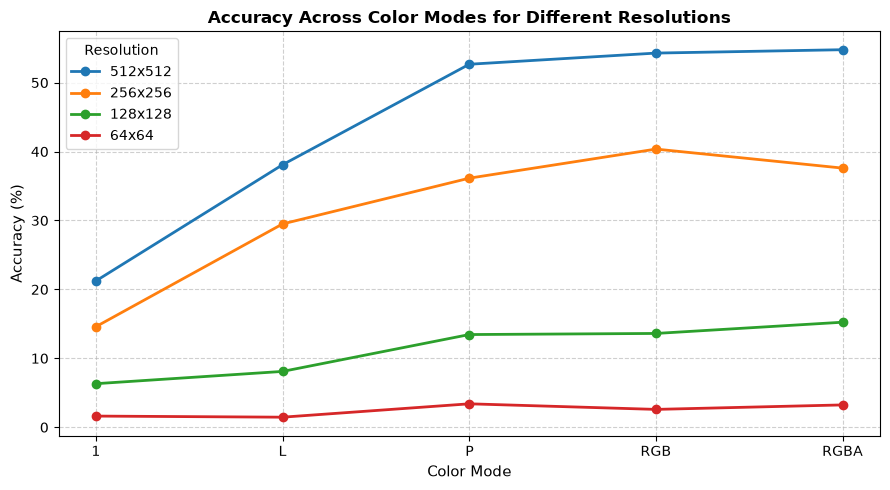

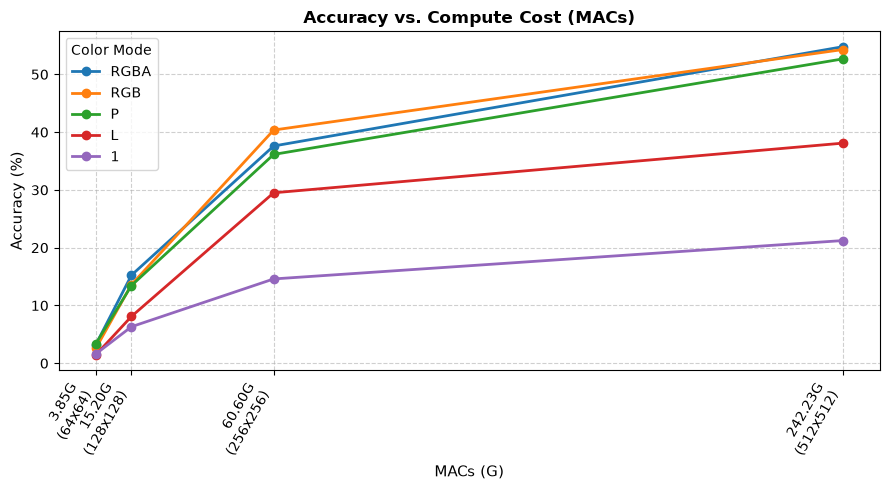

In [4]:
color_modes = ["1", "L", "P", "RGB", "RGBA"]
# Accuracy data (%) mapped to color_modes order
accuracy_data = {
    "512x512": [21.23, 38.09, 52.67, 54.29, 54.78],
    "256x256": [14.59, 29.50, 36.14, 40.36, 37.60],
    "128x128": [6.32, 8.10, 13.45, 13.61, 15.24],
    "64x64": [1.62, 1.46, 3.40, 2.59, 3.24],
}

plt.figure(figsize=(9, 5))

# Plot one line for each resolution
for res, acc in accuracy_data.items():
    plt.plot(color_modes, acc, marker="o", linewidth=2, label=res)

plt.title(
    "Accuracy Across Color Modes for Different Resolutions",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Color Mode", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Resolution")
plt.tight_layout()

plt.savefig("accuracy_vs_colormode.png", dpi=300)
plt.show()

# Updated MACs values (G) for 64x64, 128x128, 256x256, and 512x512
macs = [3.85, 15.20, 60.60, 242.23]

# Accuracy (%) per color mode as compute (MACs) scales up
accuracy_by_mode = {
    "RGBA": [3.24, 15.24, 37.60, 54.78],
    "RGB": [2.59, 13.61, 40.36, 54.29],
    "P": [3.40, 13.45, 36.14, 52.67],
    "L": [1.46, 8.10, 29.50, 38.09],
    "1": [1.62, 6.32, 14.59, 21.23],
}

plt.figure(figsize=(9, 5))

# Plot one line for each color mode across compute scale
for mode, acc in accuracy_by_mode.items():
    plt.plot(macs, acc, marker="o", linewidth=2, label=mode)

plt.title(
    "Accuracy vs. Compute Cost (MACs)", fontsize=12, fontweight="bold"
)
plt.xlabel("MACs (G)", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)

plt.xticks(
    macs,
    labels=[
        "3.85G\n(64x64)",
        "15.20G\n(128x128)",
        "60.60G\n(256x256)",
        "242.23G\n(512x512)",
    ],
    rotation=60,
    ha="right",
)

plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend(title="Color Mode")
plt.tight_layout()

plt.savefig("accuracy_vs_macs.png", dpi=300)
plt.show()

### Statistical Testing

In [5]:
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Accuracy dataset
data_accuracy = {
    "Resolution": [512] * 5 + [256] * 5 + [128] * 5 + [64] * 5,
    "ColorMode": ["RGBA", "RGB", "P", "L", "1"] * 4,
    "Accuracy": [
        54.78,
        54.29,
        52.67,
        38.09,
        21.23,  # 512x512
        37.60,
        40.36,
        36.14,
        29.50,
        14.59,  # 256x256
        15.24,
        13.61,
        13.45,
        8.10,
        6.32,  # 128x128
        3.24,
        2.59,
        3.40,
        1.46,
        1.62,  # 64x64
    ],
}

df_acc = pd.DataFrame(data_accuracy)

# Two-Way Additive ANOVA (Parametric block design)
model = ols("Accuracy ~ C(Resolution) + C(ColorMode)", data=df_acc).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print("\nTwo-Way ANOVA Table:")
print(anova_table)

# Peak VRAM dataset with updated empirical values
data_vram = {
    "Resolution": [512] * 5 + [256] * 5 + [128] * 5 + [64] * 5,
    "Pixels": [512 * 512] * 5
    + [256 * 256] * 5
    + [128 * 128] * 5
    + [64 * 64] * 5,
    "Peak_VRAM": [
        767.11,
        768.16,
        766.02,
        847.59,
        848.04,  # 512x512
        416.79,
        415.79,
        414.54,
        495.77,
        495.77,  # 256x256
        228.16,
        227.66,
        228.86,
        307.59,
        307.59,  # 128x128
        282.09,
        282.09,
        281.81,
        360.53,
        360.53,  # 64x64
    ],
}

df_vram = pd.DataFrame(data_vram)

# 1. One-Way ANOVA: Tests if group means differ across resolutions
f_stat, anova_p = stats.f_oneway(
    df_vram[df_vram["Resolution"] == 512]["Peak_VRAM"],
    df_vram[df_vram["Resolution"] == 256]["Peak_VRAM"],
    df_vram[df_vram["Resolution"] == 128]["Peak_VRAM"],
    df_vram[df_vram["Resolution"] == 64]["Peak_VRAM"],
)

# 2. Spearman Rank Correlation: Tests for a monotonic trend
rho, spearman_p = stats.spearmanr(df_vram["Pixels"], df_vram["Peak_VRAM"])

print(f"\nOne-Way ANOVA: F = {f_stat:.4f}, p = {anova_p:.4f}")
print(f"Spearman Rank Correlation: rho = {rho:.4f}, p = {spearman_p:.4f}")


Two-Way ANOVA Table:
                   sum_sq    df          F        PR(>F)
C(Resolution)  5404.31092   3.0  44.405402  9.001053e-07
C(ColorMode)    854.44153   4.0   5.265494  1.102469e-02
Residual        486.81563  12.0        NaN           NaN

One-Way ANOVA: F = 154.6474, p = 0.0000
Spearman Rank Correlation: rho = 0.8233, p = 0.0000
